# Gold Price Forecasting with Prophet — Daily Model + External Regressors

**Objective.** Forecast the daily gold price (USD/oz) over the next six months using the Kitco daily series in `gold_data_new.xlsx`, external macro/market/geopolitical regressors, and Prophet. This notebook mirrors the monthly workflow in `prophet.ipynb`, but changes the modelling frequency to **business days** and documents every cleaning, validation, and modelling decision.

**Key design choices**

- **Target:** `Kitco Price (USD)` from `gold_data_new.xlsx`. The World Gold Council monthly series is used only for QA, not as the daily target.
- **Frequency:** Business-day panel. We do not fabricate prices for missing weekdays; Prophet fits only observed target dates.
- **Horizon:** 6 months (126 business days).
- **Validation:** 24-month holdout plus four rolling 12-month walk-forward folds.
- **Regressors:** Lagged one business day to prevent same-day leakage. The final compact set is selected from the holdout and walk-forward evidence, not from in-sample fit.
- **Outputs:** Saved to `model_building/output_daily/` (forecast, metrics, cleaned panel, and figures).

## Step 0 — Setup

The notebook is self-contained and resolves the repository root whether it is launched from the repository root or from `model_building/`. All paths are relative to that root.

The environment uses `pandas`, `Prophet`, `xlrd` (for the GPR `.xls` file), `matplotlib`, and `seaborn`. Warnings from optional plotting dependencies are suppressed; command-line Stan output is reduced to errors.

In [1]:
import warnings
import logging
import re
from datetime import datetime, date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import prophet
from prophet import Prophet
from IPython.display import display

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("cmdstanpy").propagate = False
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

ROOT = Path.cwd()
if not (ROOT / "data-sources").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data-sources"
OUT = ROOT / "model_building" / "output_daily"
OUT.mkdir(parents=True, exist_ok=True)

START = pd.Timestamp("2015-02-05")
END = pd.Timestamp("2026-10-26")
HORIZON = 126
HOLDOUT_MONTHS = 24

print(f"Repository: {ROOT}")
print(f"pandas {pd.__version__} | Prophet {prophet.__version__}")
print(f"Output directory: {OUT}")

Importing plotly failed. Interactive plots will not work.


Repository: /home/kosala/git-repos/gold_prediction
pandas 3.1.0 | Prophet 1.5.0
Output directory: /home/kosala/git-repos/gold_prediction/model_building/output_daily


## Step 1 — Target cleaning and date repair

The spreadsheet is not a clean table: it has three header rows, mixed date types, duplicate dates, weekend rows, and at least one date-format typo. The cleaning order is deliberate:

1. **Parse the `dates` column first**, because it is the intended timestamp. Handle Excel datetimes, ISO strings, and dotted `dd.mm.yyyy` values.
2. If `dates` is missing or outside the known valid range, fall back to `row_date`.
3. Repair the obvious year typo `22.08.20232` -> `22.08.2023` before parsing.
4. Keep rows in `2015-02-05` -> `2026-10-26` with a numeric Kitco target.
5. Remove weekend rows.
6. Resolve duplicate dates by choosing the candidate closest to both its 21-day neighbourhood median and the WGC monthly average.
7. Flag implausible outliers and set them to missing rather than deleting the date.

The last point matters for Prophet: the model can handle a missing business day, but a bad price would distort the entire local trend.

In [2]:
def parse_any_date(value):
    if pd.isna(value):
        return pd.NaT
    if isinstance(value, (pd.Timestamp, datetime, date, np.datetime64)):
        return pd.Timestamp(value).normalize()

    if isinstance(value, (int, float, np.integer, np.floating)) and not isinstance(value, bool):
        x = float(value)
        if 10000000 <= x <= 99999999:
            try:
                return pd.Timestamp(datetime.strptime(str(int(x)), "%Y%m%d")).normalize()
            except Exception:
                pass
        if 20000 <= x <= 60000:
            return (pd.Timestamp("1899-12-30") + pd.to_timedelta(x, unit="D")).normalize()

    s = str(value).strip()
    if not s or s.lower() in {"nan", "nat", "none"}:
        return pd.NaT

    s = re.sub(r"^(\d{1,2})\.(\d{1,2})\.(\d{4})\d$", r"\1.\2.\3", s)

    if "." in s:
        for fmt in ("%d.%m.%Y", "%d.%m.%y"):
            try:
                return pd.to_datetime(s, format=fmt).normalize()
            except Exception:
                pass
    if "/" in s:
        for fmt in ("%m/%d/%Y", "%d/%m/%Y"):
            try:
                return pd.to_datetime(s, format=fmt).normalize()
            except Exception:
                pass
    try:
        return pd.to_datetime(s, format="ISO8601").normalize()
    except Exception:
        pass
    parsed = pd.to_datetime(s, errors="coerce", dayfirst=True)
    return parsed.normalize() if pd.notna(parsed) else pd.NaT


def load_wgc():
    raw = pd.read_excel(
        DATA / "Gold_price_averages_in_a range_of_currencies_since_1978.xlsx",
        sheet_name="Monthly_Avg",
        header=None,
    ).iloc[6:, [2, 3]]
    raw.columns = ["date", "wgc"]
    raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
    raw["wgc"] = pd.to_numeric(raw["wgc"], errors="coerce")
    raw = raw.dropna(subset=["date", "wgc"]).copy()
    raw["period"] = raw["date"].dt.to_period("M")
    return raw.set_index("period")["wgc"].sort_index()


def load_gold_clean():
    raw = pd.read_excel(DATA / "gold_data_new.xlsx", header=None)
    body = raw.iloc[3:].copy()
    body.columns = [
        "row_date", "dates", "pabc_24", "pabc_22", "local_24",
        "local_24_biscuit", "local_22", "global_24_biscuit", "global_22",
        "usd_fx", "kitco_usd", "max_ltv", "last_updated", "gap", "x", "y",
    ]

    body["d_dates"] = body["dates"].map(parse_any_date)
    body["d_row"] = body["row_date"].map(parse_any_date)
    body["ds"] = body["d_dates"]
    bad = body["ds"].isna() | (body["ds"] < START) | (body["ds"] > END)
    usable_row = body["d_row"].notna() & (body["d_row"] >= START) & (body["d_row"] <= END)
    body.loc[bad & usable_row, "ds"] = body.loc[bad & usable_row, "d_row"]
    body["y"] = pd.to_numeric(body["kitco_usd"], errors="coerce")

    filtered = body[(body["ds"] >= START) & (body["ds"] <= END) & body["y"].notna()].copy()
    weekend_rows = int((filtered["ds"].dt.day_of_week >= 5).sum())
    cand = filtered[filtered["ds"].dt.day_of_week < 5].copy()

    counts = cand.groupby("ds").size()
    duplicate_groups = int((counts > 1).sum())
    duplicate_rows_removed = int((counts - 1).clip(lower=0).sum())

    wgc = load_wgc()
    cand["period"] = cand["ds"].dt.to_period("M")
    cand["wgc_m"] = cand["period"].map(wgc)

    single = cand.loc[~cand.duplicated("ds", keep=False)].set_index("ds")["y"].sort_index()
    neighbourhood = single.rolling("21D", center=True, min_periods=3).median()
    cand["neigh"] = cand["ds"].map(neighbourhood)
    cand["score"] = (
        (cand["y"] / cand["neigh"] - 1).abs().fillna(0)
        + (cand["y"] / cand["wgc_m"] - 1).abs().fillna(0)
    )

    resolved = (
        cand.sort_values(["ds", "score", "y"])
        .drop_duplicates("ds", keep="first")
        .sort_values("ds")
        .reset_index(drop=True)
    )

    neighbourhood2 = (
        resolved.set_index("ds")["y"]
        .rolling("21D", center=True, min_periods=3)
        .median()
    )
    resolved["neigh"] = neighbourhood2.values
    resolved["wgc_ratio"] = resolved["y"] / resolved["wgc_m"]
    resolved["neigh_ratio"] = resolved["y"] / resolved["neigh"]
    outlier_mask = (
        (resolved["wgc_ratio"] < 0.80)
        | (resolved["wgc_ratio"] > 1.20)
        | (resolved["neigh_ratio"] < 0.85)
        | (resolved["neigh_ratio"] > 1.15)
    )
    outliers = resolved.loc[
        outlier_mask, ["ds", "y", "wgc_m", "neigh", "wgc_ratio", "neigh_ratio"]
    ].copy()
    resolved.loc[outlier_mask, "y"] = np.nan

    final = resolved.dropna(subset=["y"])[["ds", "y"]].reset_index(drop=True)
    bdays = pd.bdate_range(final["ds"].min(), final["ds"].max())
    qa = {
        "raw_body_rows": len(body),
        "rows_with_usable_date": int(body["ds"].notna().sum()),
        "rows_in_range_with_target": len(filtered),
        "weekend_rows_removed": weekend_rows,
        "duplicate_groups": duplicate_groups,
        "duplicate_rows_removed": duplicate_rows_removed,
        "outliers_flagged": int(outlier_mask.sum()),
        "final_observations": len(final),
        "final_start": final["ds"].min(),
        "final_end": final["ds"].max(),
        "missing_business_days": int(len(bdays) - len(final)),
    }
    return final, qa, outliers


gold, target_qa, outliers = load_gold_clean()

print("Target QA")
for key, value in target_qa.items():
    print(f"  {key}: {value}")

if len(outliers):
    display(outliers)
else:
    print("No outliers flagged.")

Target QA
  raw_body_rows: 2864
  rows_with_usable_date: 2859
  rows_in_range_with_target: 2834
  weekend_rows_removed: 17
  duplicate_groups: 160
  duplicate_rows_removed: 160
  outliers_flagged: 1
  final_observations: 2656
  final_start: 2015-02-05 00:00:00
  final_end: 2026-10-26 00:00:00
  missing_business_days: 402


,ds,y,wgc_m,neigh,wgc_ratio,neigh_ratio
232,2016-05-31,123.2,1259.4,1213.6,0.097824,0.101516


### Target QA and WGC cross-check

The WGC monthly averages are a different source and a different frequency, so they are not expected to match exactly. They are used only to catch gross cleaning errors. A correlation near 1 and a small mean absolute difference indicate that the daily target extraction is sound.

{'months_compared': 140, 'correlation': np.float64(0.999958), 'mean_absolute_difference_usd': np.float64(4.99436), 'median_absolute_percentage_error': np.float64(0.153901)}


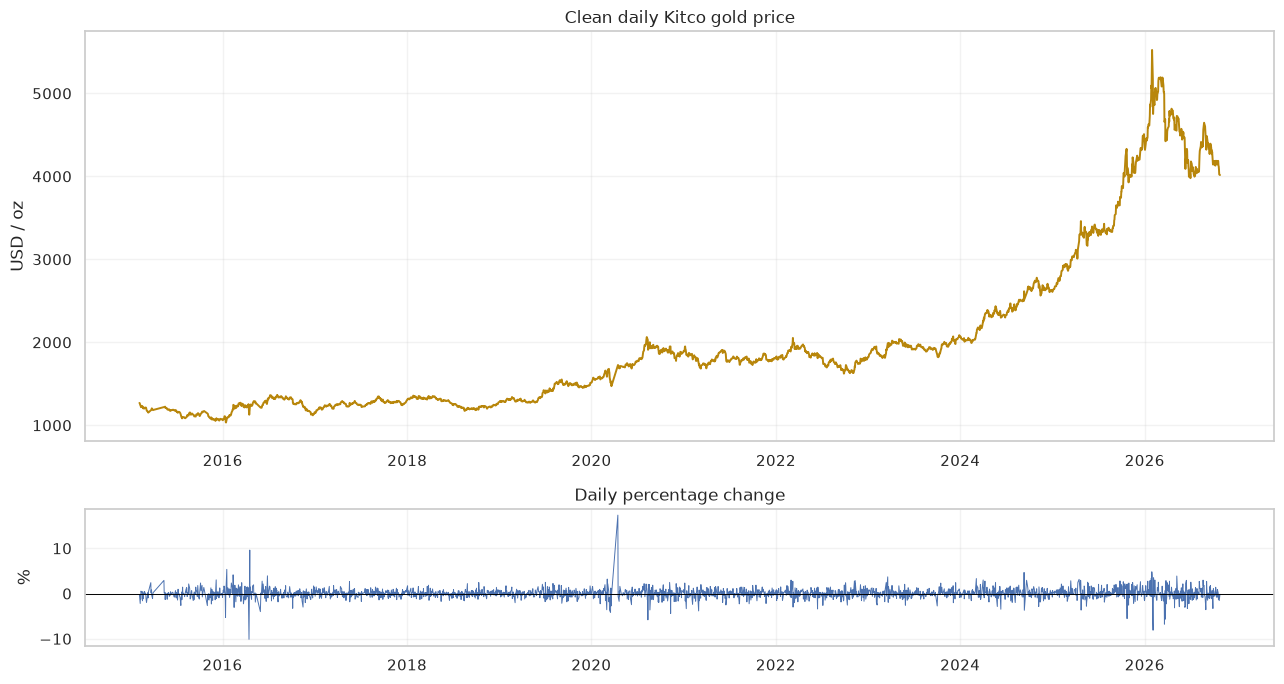

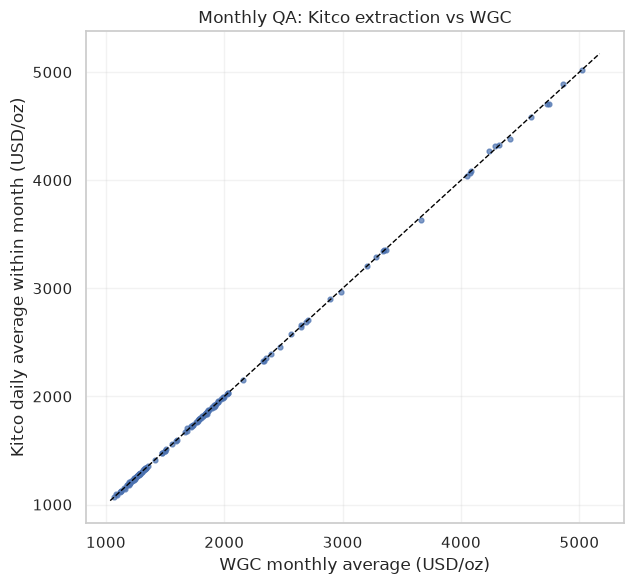

In [3]:
wgc = load_wgc()

monthly_avg = gold.set_index("ds")["y"].resample("MS").mean()
wgc_aligned = wgc.reindex(monthly_avg.index.to_period("M"))
qa_monthly = pd.DataFrame({
    "kitco_monthly_avg": monthly_avg.values,
    "wgc_monthly": wgc_aligned.values,
}, index=monthly_avg.index).dropna()
qa_monthly["difference"] = qa_monthly["kitco_monthly_avg"] - qa_monthly["wgc_monthly"]
qa_monthly["pct_error"] = qa_monthly["difference"].abs() / qa_monthly["wgc_monthly"] * 100

qa_stats = {
    "months_compared": len(qa_monthly),
    "correlation": qa_monthly[["kitco_monthly_avg", "wgc_monthly"]].corr().iloc[0, 1],
    "mean_absolute_difference_usd": qa_monthly["difference"].abs().mean(),
    "median_absolute_percentage_error": qa_monthly["pct_error"].median(),
}
print({k: round(v, 6) if isinstance(v, float) else v for k, v in qa_stats.items()})

fig, axes = plt.subplots(2, 1, figsize=(13, 7), height_ratios=[3, 1])
axes[0].plot(gold["ds"], gold["y"], color="#b8860b", lw=1.4)
axes[0].set_title("Clean daily Kitco gold price")
axes[0].set_ylabel("USD / oz")
axes[0].grid(alpha=0.25)

returns = gold.set_index("ds")["y"].pct_change() * 100
axes[1].plot(returns.index, returns.values, color="#4c72b0", lw=0.7)
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set_title("Daily percentage change")
axes[1].set_ylabel("%")
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "gold_history_daily.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(qa_monthly["wgc_monthly"], qa_monthly["kitco_monthly_avg"], s=12, alpha=0.7)
lo = min(qa_monthly["wgc_monthly"].min(), qa_monthly["kitco_monthly_avg"].min()) * 0.97
hi = max(qa_monthly["wgc_monthly"].max(), qa_monthly["kitco_monthly_avg"].max()) * 1.03
ax.plot([lo, hi], [lo, hi], ls="--", color="black", lw=1)
ax.set_xlabel("WGC monthly average (USD/oz)")
ax.set_ylabel("Kitco daily average within month (USD/oz)")
ax.set_title("Monthly QA: Kitco extraction vs WGC")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "wgc_qa_daily.png", dpi=150, bbox_inches="tight")
plt.show()

qa_monthly.to_csv(OUT / "wgc_monthly_qa.csv")

## Step 2 — External regressors and coverage

The candidate set covers the main channels discussed in the gold literature:

- **Real interest rates / policy:** 10-year Treasury yield, Fed funds rate, CPI year-over-year.
- **Opportunity cost / dollar:** US Dollar Index.
- **Commodity and risk channels:** Brent crude, S&P 500, geopolitical risk (GPR).
- **Oil:** Brent is the primary oil measure. WTI is kept for comparison but is not used in the final model because it is highly collinear with Brent and had negative prices in 2020.

Data quirks handled here:

- GPR is daily and uses a `DAY` integer (`YYYYMMDD`), not the `Date` text column.
- DXY is monthly in this file, not daily, despite the generic documentation.
- Fed funds and CPI are monthly; they are aligned to the date they would have been released, not to the reference month.
- Some historical CSVs contain weekend rows; those are removed before alignment.

In [4]:
def load_csv_series(filename, date_col, value_col, date_fmt=None, na_values=None):
    df = pd.read_csv(DATA / filename, na_values=na_values)
    if date_fmt is None:
        dates = pd.to_datetime(df[date_col], errors="coerce")
    else:
        dates = pd.to_datetime(df[date_col], format=date_fmt, errors="coerce")
    values = pd.to_numeric(
        df[value_col].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )
    series = pd.Series(values.values, index=dates).dropna().sort_index()
    return series[~series.index.duplicated(keep="last")]


def load_gpr():
    df = pd.read_excel(DATA / "data_gpr_daily_recent.xls", engine="xlrd")
    df["ds"] = pd.to_datetime(df["DAY"].astype(str), format="%Y%m%d", errors="coerce")
    df = df.dropna(subset=["ds"]).set_index("ds").sort_index()
    mapping = {
        "gpr": "GPRD",
        "gpr_act": "GPRD_ACT",
        "gpr_threat": "GPRD_THREAT",
        "gpr_ma7": "GPRD_MA7",
        "gpr_ma30": "GPRD_MA30",
    }
    return pd.DataFrame({
        name: pd.to_numeric(df[col], errors="coerce") for name, col in mapping.items()
    })


def load_cpi():
    raw = pd.read_excel(DATA / "SeriesReport-20261028041515_7e01eb-use.xlsx", header=None)
    header_row = raw.index[raw[0].astype(str).str.strip().eq("Series ID")][0]
    cpi = raw.iloc[header_row + 1:].copy()
    cpi.columns = ["series", "year", "period", "value"]
    cpi = cpi.dropna(subset=["year"])
    cpi["date"] = pd.to_datetime(
        cpi["year"].astype(int).astype(str) + cpi["period"].astype(str).str.replace("M", "-"),
        format="%Y-%m",
        errors="coerce",
    )
    cpi["value"] = pd.to_numeric(cpi["value"], errors="coerce")
    cpi = cpi.dropna(subset=["date", "value"]).set_index("date").sort_index()["value"]
    return cpi


gpr = load_gpr()
sp500 = load_csv_series("S&P 500 Historical Data.csv", "Date", "Price", date_fmt="%m/%d/%Y")
ust10y = load_csv_series(
    "United States 10-Year Bond Yield Historical Data-use.csv", "Date", "Price", date_fmt="%m/%d/%Y"
)
ust10y = ust10y[ust10y.index.day_of_week < 5]
brent = load_csv_series("DCOILBRENTEU.csv", "observation_date", "DCOILBRENTEU", na_values=".")
wti = load_csv_series("DCOILWTICO.csv", "observation_date", "DCOILWTICO", na_values=".")
dxy = load_csv_series("US Dollar Index Historical Data.csv", "Date", "Price", date_fmt="%m/%d/%Y")
fed = load_csv_series("FEDFUNDS.csv", "observation_date", "FEDFUNDS")
cpi = load_cpi()
cpi_yoy_monthly = (cpi / cpi.shift(12) - 1) * 100

dxy_m = dxy.copy()
dxy_m.index = dxy_m.index.to_period("M").to_timestamp("M")
dxy_m = dxy_m[~dxy_m.index.duplicated(keep="last")].sort_index()

fed_m = fed.copy()
fed_m.index = fed_m.index.to_period("M").to_timestamp("M")
fed_m = fed_m[~fed_m.index.duplicated(keep="last")].sort_index()

cpi_m = cpi_yoy_monthly.dropna().copy()
cpi_m.index = cpi_m.index.to_period("M").to_timestamp("M")
cpi_m = cpi_m[~cpi_m.index.duplicated(keep="last")].sort_index()

coverage = []
for name, series in [
    ("Gold target", gold.set_index("ds")["y"]),
    ("GPR daily", gpr["gpr"]),
    ("S&P 500", sp500),
    ("US 10Y yield", ust10y),
    ("Brent (FRED)", brent),
    ("WTI (FRED)", wti),
    ("US Dollar Index (monthly)", dxy_m),
    ("Fed funds (monthly)", fed_m),
    ("CPI YoY (monthly)", cpi_m),
    ("WGC monthly", wgc),
]:
    coverage.append({
        "series": name,
        "start": series.index.min(),
        "end": series.index.max(),
        "observations": len(series),
    })

coverage_df = pd.DataFrame(coverage)
display(coverage_df)

latest_rows = []
for name, series in [
    ("US 10Y yield", ust10y),
    ("Brent (FRED)", brent),
    ("US Dollar Index (monthly)", dxy_m),
    ("Fed funds (monthly)", fed_m),
    ("CPI YoY (monthly)", cpi_m),
]:
    latest_rows.append({
        "series": name,
        "last_date": series.index.max(),
        "last_value": series.iloc[-1],
    })
display(pd.DataFrame(latest_rows))

,series,start,end,observations
0,Gold target,2015-02-05 00:00:00,2026-10-26 00:00:00,2656
1,GPR daily,1985-01-01 00:00:00,2026-10-26 00:00:00,15274
2,S&P 500,2015-01-02 00:00:00,2026-10-27 00:00:00,2972
3,US 10Y yield,2010-01-28 00:00:00,2026-10-28 00:00:00,4315
4,Brent (FRED),1987-05-20 00:00:00,2026-10-20 00:00:00,9112
5,WTI (FRED),1986-01-02 00:00:00,2026-10-20 00:00:00,9527
6,US Dollar Index (monthly),1995-02-28 00:00:00,2026-10-31 00:00:00,381
7,Fed funds (monthly),1954-07-31 00:00:00,2026-09-30 00:00:00,867
8,CPI YoY (monthly),2001-01-31 00:00:00,2026-09-30 00:00:00,308
9,WGC monthly,1978-01,2026-09,585


,series,last_date,last_value
0,US 10Y yield,2026-10-28,5.01900
1,Brent (FRED),2026-10-20,115.22000
2,US Dollar Index (monthly),2026-10-31,102.10000
3,Fed funds (monthly),2026-09-30,3.75000
4,CPI YoY (monthly),2026-09-30,4.02331


## Step 3 — Business-day panel and release-lag alignment

Daily market series are reindexed to business days and forward-filled. Monthly policy and inflation series are aligned to **release dates**, not reference months:

| Series | Release rule | Why |
|---|---|---|
| DXY | month-end + 1 day | Monthly index value is not available until the month closes. |
| Fed funds | month-end + 1 day | Monthly average is published after month-end. |
| CPI / CPI YoY | month-end + 15 days | Approximate mid-month release lag. |

This avoids look-ahead bias. For example, September CPI is not treated as known until mid-October. The panel still contains missing target values; those dates are intentionally left missing rather than interpolated.

In [5]:
def monthly_asof(series, release_days, target_index):
    s = series.dropna().copy()
    s.index = s.index.to_period("M")
    release = s.index.to_timestamp(how="end").normalize() + pd.Timedelta(days=release_days)
    frame = pd.DataFrame({"release": release, "value": s.values}).sort_values("release")
    query = pd.DataFrame({"ds": target_index}).sort_values("ds")
    merged = pd.merge_asof(
        query, frame, left_on="ds", right_on="release", direction="backward"
    )
    return pd.Series(merged["value"].values, index=merged["ds"].values)


bdays = pd.bdate_range(gold["ds"].min(), gold["ds"].max())
panel = pd.DataFrame(index=bdays)
panel.index.name = "ds"
panel["gold"] = gold.set_index("ds")["y"].reindex(bdays)

for column in gpr.columns:
    panel[column] = gpr[column].reindex(bdays).ffill()

for name, series in [
    ("sp500", sp500),
    ("ust10y", ust10y),
    ("brent", brent),
    ("wti", wti),
]:
    panel[name] = series.reindex(bdays).ffill()

panel["dxy"] = monthly_asof(dxy_m, 1, bdays)
panel["fed_funds"] = monthly_asof(fed_m, 1, bdays)
panel["cpi"] = monthly_asof(cpi, 15, bdays)
panel["cpi_yoy"] = monthly_asof(cpi_m, 15, bdays)
panel["real_yield"] = panel["ust10y"] - panel["cpi_yoy"]

print(f"Panel: {panel.shape[0]:,} business days, {panel.shape[1]} columns")
print(f"Range: {panel.index.min().date()} -> {panel.index.max().date()}")
display(panel.isna().sum().to_frame("missing_values").T)
display(panel[["gold", "ust10y", "dxy", "brent", "gpr_ma7", "sp500", "fed_funds", "cpi_yoy"]].tail(5))

Panel: 3,058 business days, 15 columns
Range: 2015-02-05 -> 2026-10-26


,gold,gpr,gpr_act,gpr_threat,gpr_ma7,gpr_ma30,sp500,ust10y,brent,wti,dxy,fed_funds,cpi,cpi_yoy,real_yield
missing_values,402,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,gold,ust10y,dxy,brent,gpr_ma7,sp500,fed_funds,cpi_yoy
ds,,,,,,,,
2026-10-20,4130.1,5.117,101.45,115.22,155.064514,7712.57,3.75,4.02331
2026-10-21,4121.8,5.146,101.45,115.22,170.964554,7757.17,3.75,4.02331
2026-10-22,4085.8,4.953,101.45,115.22,176.380737,7663.43,3.75,4.02331
2026-10-23,4022.5,4.988,101.45,115.22,188.300339,7623.68,3.75,4.02331
2026-10-26,4015.8,4.986,101.45,115.22,181.415527,7676.77,3.75,4.02331


### Regressor history

The series are plotted normalized to 100 at the start of the sample. This is only a visual sanity check; the model uses the original levels, not the normalized values.

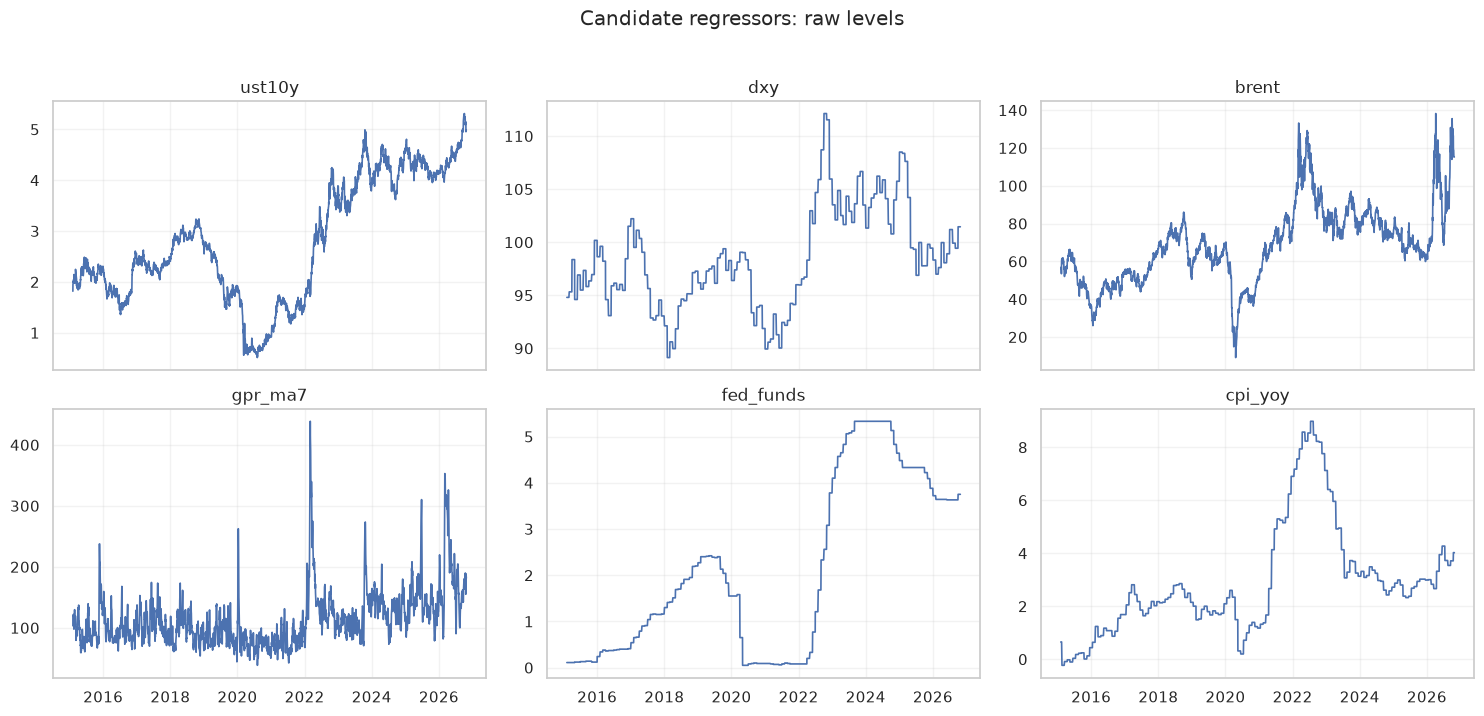

In [6]:
plot_cols = ["ust10y", "dxy", "brent", "gpr_ma7", "fed_funds", "cpi_yoy"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, column in zip(axes.ravel(), plot_cols):
    ax.plot(panel.index, panel[column], lw=1.2, color="#4c72b0")
    ax.set_title(column)
    ax.grid(alpha=0.25)
fig.suptitle("Candidate regressors: raw levels", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "regressors_history_daily.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 4 — Feature engineering, correlations, and daily lead-lag screening

Three diagnostics are used, each for a different purpose:

1. **Level correlations** show shared trends. They are informative but can be spurious; two series that both rise over time will correlate even without a causal relationship.
2. **20-business-day change correlations** remove most of the trend and show co-movement at a meaningful forecast horizon.
3. **Cross-correlation (CCF) of daily changes** checks whether a regressor leads gold. The strongest daily relationship is the 10-year yield at a one-day lead, but its magnitude is modest (`r ≈ -0.27`). This is why the model does not rely on CCF alone; it uses out-of-sample validation.

The CCF is computed with an explicit finite-value mask and pairwise deletion. This avoids the all-NaN failure that occurs when `inf` values from log transforms or index misalignment enter the correlation.

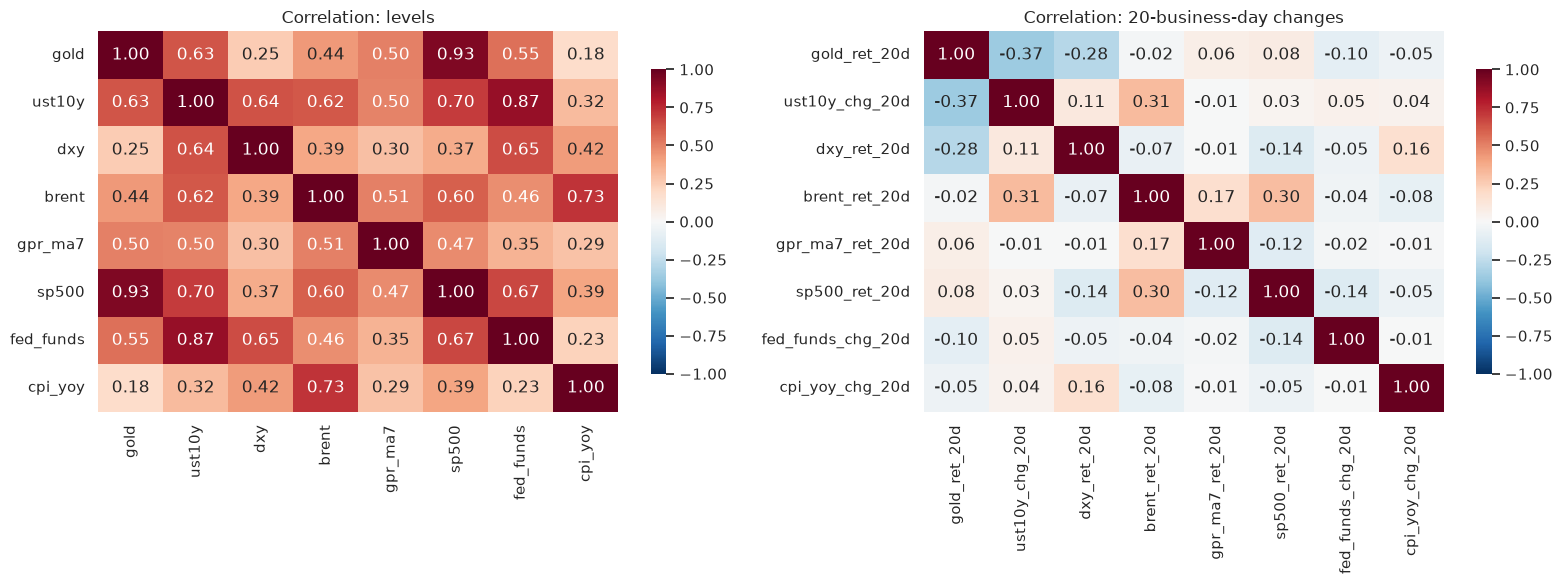

,feature,lag,r,n
11,ust10y_chg_1d,1,-0.274533,2379
53,brent_ret_1d,1,0.075463,2379
110,cpi_yoy_chg_1d,-5,0.062309,2375
43,brent_ret_1d,-9,-0.057054,2371
21,dxy_ret_1d,-10,-0.051166,2370
71,gpr_ma7_ret_1d,-2,0.045612,2378
23,dxy_ret_1d,-8,-0.043032,2372
12,ust10y_chg_1d,2,-0.041646,2378
25,dxy_ret_1d,-6,-0.041354,2374
28,dxy_ret_1d,-3,-0.041256,2377


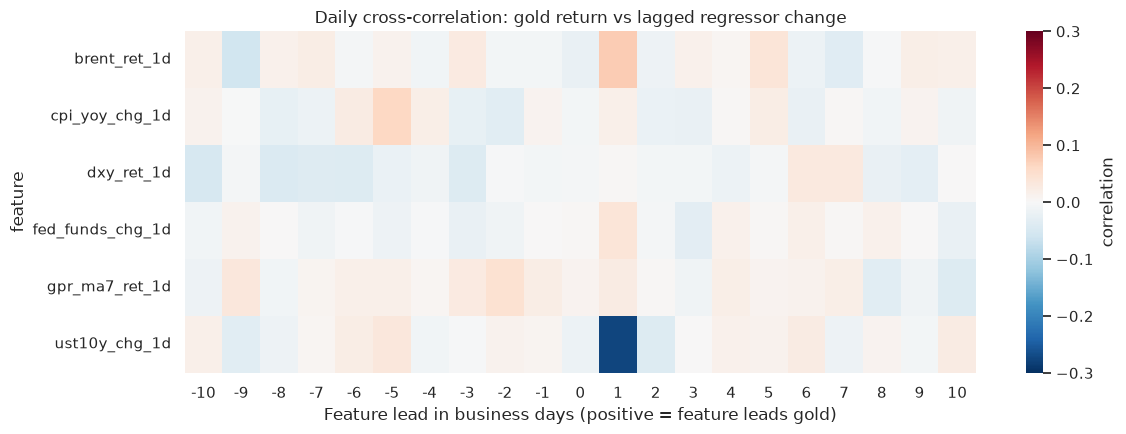

In [7]:
def add_features(panel):
    p = panel.copy()

    p["gold_log"] = np.log(p["gold"].where(p["gold"] > 0))
    p["gold_ret_1d"] = p["gold_log"].diff(1)
    p["gold_ret_5d"] = p["gold_log"].diff(5)
    p["gold_ret_20d"] = p["gold_log"].diff(20)
    p["gold_vol_20d"] = p["gold_ret_1d"].rolling(20).std()

    for column in ["sp500", "brent", "dxy"]:
        p[column + "_log"] = np.log(p[column].where(p[column] > 0))
        for horizon in (1, 5, 20, 60, 252):
            p[f"{column}_ret_{horizon}d"] = p[column + "_log"].diff(horizon)

    for horizon in (1, 5, 20, 60, 252):
        p[f"wti_chg_{horizon}d"] = p["wti"].diff(horizon)

    for column in ["gpr", "gpr_ma7", "gpr_ma30"]:
        for horizon in (1, 5, 20, 60, 252):
            p[f"{column}_ret_{horizon}d"] = p[column].diff(horizon)

    for column in ["ust10y", "fed_funds", "cpi_yoy", "real_yield"]:
        for horizon in (1, 5, 20, 60, 252):
            p[f"{column}_chg_{horizon}d"] = p[column].diff(horizon)

    for column in ["gpr", "gpr_ma7", "gpr_threat", "brent", "dxy", "ust10y", "sp500"]:
        p[f"{column}_ma20"] = p[column].rolling(20).mean()
        p[f"{column}_sd20"] = p[column].rolling(20).std()
        p[f"{column}_z20"] = (p[column] - p[f"{column}_ma20"]) / p[f"{column}_sd20"]

    return p


feature_panel = add_features(panel)

level_cols = ["gold", "ust10y", "dxy", "brent", "gpr_ma7", "sp500", "fed_funds", "cpi_yoy"]
change_cols = [
    "gold_ret_20d", "ust10y_chg_20d", "dxy_ret_20d", "brent_ret_20d",
    "gpr_ma7_ret_20d", "sp500_ret_20d", "fed_funds_chg_20d", "cpi_yoy_chg_20d",
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(
    feature_panel[level_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, center=0, ax=axes[0], cbar_kws={"shrink": 0.8},
)
axes[0].set_title("Correlation: levels")
sns.heatmap(
    feature_panel[change_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, center=0, ax=axes[1], cbar_kws={"shrink": 0.8},
)
axes[1].set_title("Correlation: 20-business-day changes")
fig.tight_layout()
fig.savefig(OUT / "correlation_daily.png", dpi=150, bbox_inches="tight")
plt.show()


def ccf_table(df, target, features, max_lag=10):
    rows = []
    for feature in features:
        for lag in range(-max_lag, max_lag + 1):
            pair = pd.concat([df[target], df[feature].shift(lag)], axis=1)
            pair = pair.replace([np.inf, -np.inf], np.nan).dropna()
            if len(pair) > 30:
                r = pair.iloc[:, 0].corr(pair.iloc[:, 1])
                if np.isfinite(r):
                    rows.append({"feature": feature, "lag": lag, "r": r, "n": len(pair)})
    return pd.DataFrame(rows)


ccf_features = [
    "ust10y_chg_1d", "dxy_ret_1d", "brent_ret_1d",
    "gpr_ma7_ret_1d", "fed_funds_chg_1d", "cpi_yoy_chg_1d",
]
ccf = ccf_table(feature_panel, "gold_ret_1d", ccf_features, max_lag=10)
ccf_top = ccf.assign(abs_r=ccf["r"].abs()).sort_values("abs_r", ascending=False).head(10)
display(ccf_top[["feature", "lag", "r", "n"]])

pivot = ccf.pivot(index="feature", columns="lag", values="r")
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(
    pivot, cmap="RdBu_r", center=0, vmin=-0.30, vmax=0.30,
    ax=ax, cbar_kws={"label": "correlation"},
)
ax.set_title("Daily cross-correlation: gold return vs lagged regressor change")
ax.set_xlabel("Feature lead in business days (positive = feature leads gold)")
fig.tight_layout()
fig.savefig(OUT / "ccf_daily.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 5 — Model design, holdout, and candidate regressor sets

The model is a **log-price Prophet** with multiplicative seasonality. The log transform makes the error metric approximately a percentage error, which is appropriate for gold's long-run level shift. The model includes yearly seasonality but not weekly seasonality: with a business-day target and a 6-month horizon, weekly effects are not economically meaningful.

All regressors are lagged one business day. The holdout is the last 24 months. Candidate sets are evaluated with the **anchored** forecast, because the final production forecast is anchored to the latest observed price (explained below). Raw errors are also reported for transparency.

**Anchoring.** Prophet's smooth trend can lag a sharp move in the final week. The final forecast is therefore shifted by the log residual at the last training observation:

`forecast_adjusted = exp(log_forecast) * (last_actual / last_fitted)`

This uses only information available at the forecast origin. It prevents a discontinuous jump at the start of the forecast and is a standard nowcast correction. The holdout evaluation applies the same rule at the holdout cutoff.

In [8]:
ALL_REGS = ["ust10y", "dxy", "brent", "gpr_ma7", "sp500", "fed_funds", "cpi_yoy"]
FINAL_REGS = ["ust10y", "dxy", "fed_funds", "cpi_yoy"]

model_df = feature_panel[["gold"] + ALL_REGS].dropna().copy()
for column in ALL_REGS:
    model_df[column] = model_df[column].shift(1)
model_df = model_df.dropna().reset_index()
model_df = model_df[["ds", "gold"] + ALL_REGS]

HOLDOUT_START = model_df["ds"].max() - pd.DateOffset(months=HOLDOUT_MONTHS)
print(f"Model sample: {len(model_df):,} rows")
print(f"Train start: {model_df['ds'].min().date()}")
print(f"Holdout: {HOLDOUT_START.date()} -> {model_df['ds'].max().date()}")


def error_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    return {
        "MAPE": float(np.mean(np.abs(error / actual)) * 100),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAE": float(np.mean(np.abs(error))),
    }


def fit_and_evaluate(regressors, cps, holdout_start, horizon_months=24):
    train = model_df[model_df["ds"] < holdout_start].copy()
    end = holdout_start + pd.DateOffset(months=horizon_months)
    test = model_df[(model_df["ds"] >= holdout_start) & (model_df["ds"] < end)].copy()

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=cps,
        interval_width=0.95,
        seasonality_mode="multiplicative",
    )
    for regressor in regressors:
        model.add_regressor(regressor)

    train_log = train.copy()
    train_log["y"] = np.log(train_log["gold"])
    model.fit(train_log)

    train_fit = model.predict(train_log[["ds"] + regressors])
    last_fitted = np.exp(train_fit["yhat"].iloc[-1])
    last_actual = train["gold"].iloc[-1]
    anchor_ratio = last_actual / last_fitted

    forecast = model.predict(test[["ds"] + regressors])
    raw_prediction = np.exp(forecast["yhat"].values)
    anchored_prediction = raw_prediction * anchor_ratio

    test_out = test[["ds", "gold"]].copy()
    test_out["pred_raw"] = raw_prediction
    test_out["pred"] = anchored_prediction
    test_out["resid"] = test_out["pred"] - test_out["gold"]

    result = {
        "test": test_out,
        "model": model,
        "anchor_ratio": anchor_ratio,
        "train_n": len(train),
        "test_n": len(test),
    }
    result.update(error_metrics(test_out["gold"], test_out["pred"]))
    raw_metrics = error_metrics(test_out["gold"], test_out["pred_raw"])
    result["MAPE_raw"] = raw_metrics["MAPE"]
    result["RMSE_raw"] = raw_metrics["RMSE"]
    return result


candidate_sets = {
    "No regressors": [],
    "10Y + DXY": ["ust10y", "dxy"],
    "10Y + DXY + Brent + GPR": ["ust10y", "dxy", "brent", "gpr_ma7"],
    "Full 7-regressor": ALL_REGS,
    "Selected 4-regressor": FINAL_REGS,
}

rows = []
for name, regressors in candidate_sets.items():
    result = fit_and_evaluate(regressors, cps=0.05, holdout_start=HOLDOUT_START)
    rows.append({
        "model": name,
        "n_regressors": len(regressors),
        "train_n": result["train_n"],
        "test_n": result["test_n"],
        "MAPE_anchored": result["MAPE"],
        "RMSE_anchored": result["RMSE"],
        "MAE_anchored": result["MAE"],
        "MAPE_raw": result["MAPE_raw"],
        "anchor_ratio": result["anchor_ratio"],
    })

model_comparison = pd.DataFrame(rows).sort_values("MAPE_anchored").reset_index(drop=True)
display(model_comparison)
model_comparison.to_csv(OUT / "model_comparison_daily.csv", index=False)

selected_row = model_comparison[model_comparison["model"] == "Selected 4-regressor"].iloc[0]
print(f"Selected holdout MAPE: {selected_row['MAPE_anchored']:.2f}%")
print(f"Selected anchor ratio at cutoff: {selected_row['anchor_ratio']:.4f}")

Model sample: 2,655 rows
Train start: 2015-02-06
Holdout: 2024-10-26 -> 2026-10-26


,model,n_regressors,train_n,test_n,MAPE_anchored,RMSE_anchored,MAE_anchored,MAPE_raw,anchor_ratio
0,Selected 4-regressor,4,2181,473,6.275827,413.629736,273.446332,9.209335,1.052445
1,Full 7-regressor,7,2181,473,7.717865,480.922523,328.899873,11.650612,1.058691
2,10Y + DXY + Brent + GPR,4,2181,473,11.100577,625.367446,473.986263,17.735285,1.082264
3,No regressors,0,2181,473,11.892397,686.032067,511.242505,19.988747,1.115758
4,10Y + DXY,2,2181,473,12.023827,670.724583,516.521075,17.972810,1.073923


Selected holdout MAPE: 6.28%
Selected anchor ratio at cutoff: 1.0524


## Step 6 — Changepoint-prior sensitivity

`changepoint_prior_scale` controls how flexible the trend is. On daily data, a smaller value produces a smoother long-run trend; a larger value allows more regime shifts and can overfit. The selected value should be stable across a reasonable grid, not the single best number from one holdout.

,changepoint_prior_scale,MAPE_anchored,RMSE_anchored,MAE_anchored,MAPE_raw
0,0.01,6.309808,419.069209,274.050122,9.202141
1,0.05,6.275827,413.629736,273.446332,9.209335
2,0.20,6.355908,418.536103,276.927833,9.347776


Selected changepoint_prior_scale = 0.05


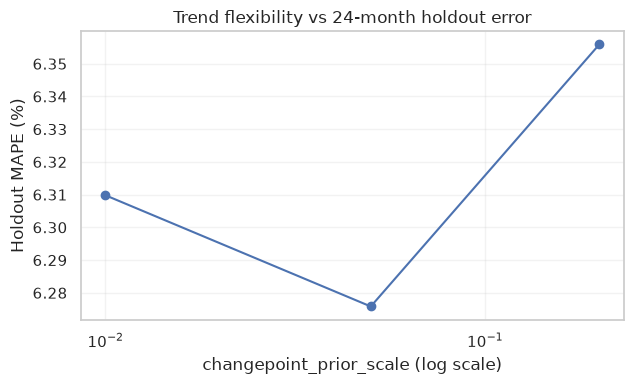

In [9]:
cps_rows = []
for cps in [0.01, 0.05, 0.20]:
    result = fit_and_evaluate(FINAL_REGS, cps=cps, holdout_start=HOLDOUT_START)
    cps_rows.append({
        "changepoint_prior_scale": cps,
        "MAPE_anchored": result["MAPE"],
        "RMSE_anchored": result["RMSE"],
        "MAE_anchored": result["MAE"],
        "MAPE_raw": result["MAPE_raw"],
    })

cps_table = pd.DataFrame(cps_rows)
display(cps_table)
cps_table.to_csv(OUT / "cps_sensitivity_daily.csv", index=False)

BEST_CPS = 0.05
print(f"Selected changepoint_prior_scale = {BEST_CPS}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(cps_table["changepoint_prior_scale"], cps_table["MAPE_anchored"], marker="o")
ax.set_xscale("log")
ax.set_xlabel("changepoint_prior_scale (log scale)")
ax.set_ylabel("Holdout MAPE (%)")
ax.set_title("Trend flexibility vs 24-month holdout error")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "cps_sensitivity_daily.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 7 — Rolling walk-forward validation

A single 24-month holdout can be lucky or unlucky. Four expanding-window folds test the same specification on different 12-month periods:

- 2022-10 -> 2023-10
- 2023-10 -> 2024-10
- 2024-10 -> 2025-10
- 2025-10 -> 2026-10

Each fold trains only on data available before its cutoff. The mean and the spread across folds are both reported; the spread is a reminder that forecast accuracy is regime-dependent.

,validation_start,validation_end,train_n,test_n,MAPE_anchored,RMSE_anchored,MAE_anchored,anchor_ratio
0,2022-10-26,2023-10-24,1725,232,5.810796,121.709094,111.081151,1.012030
1,2023-10-26,2024-10-25,1957,224,4.319019,119.538547,93.559597,1.052378
2,2024-10-26,2025-10-24,2181,235,2.641123,139.465980,90.393105,1.052445
3,2025-10-26,2026-10-23,2416,238,11.380123,588.361982,498.984752,1.061092


Walk-forward mean metrics
MAPE_anchored      6.038
RMSE_anchored    242.269
MAE_anchored     198.505


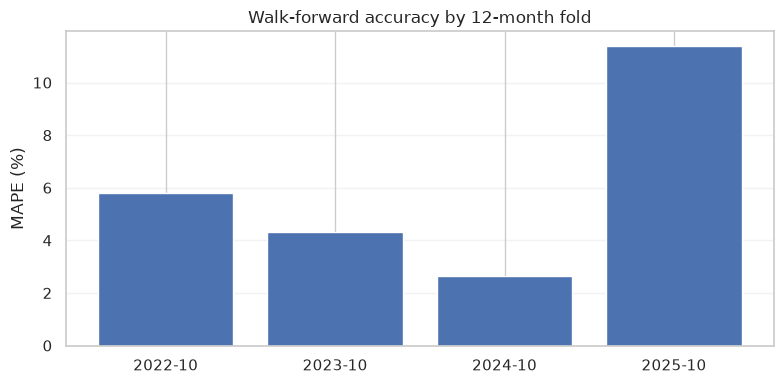

In [10]:
wf_cuts = [
    pd.Timestamp("2022-10-26"),
    pd.Timestamp("2023-10-26"),
    pd.Timestamp("2024-10-26"),
    pd.Timestamp("2025-10-26"),
]
wf_rows = []
for cutoff in wf_cuts:
    result = fit_and_evaluate(
        FINAL_REGS, cps=BEST_CPS, holdout_start=cutoff, horizon_months=12
    )
    wf_rows.append({
        "validation_start": cutoff,
        "validation_end": result["test"]["ds"].max(),
        "train_n": result["train_n"],
        "test_n": result["test_n"],
        "MAPE_anchored": result["MAPE"],
        "RMSE_anchored": result["RMSE"],
        "MAE_anchored": result["MAE"],
        "anchor_ratio": result["anchor_ratio"],
    })

wf_table = pd.DataFrame(wf_rows)
display(wf_table)
wf_table.to_csv(OUT / "walk_forward_metrics_daily.csv", index=False)

wf_mean = wf_table[["MAPE_anchored", "RMSE_anchored", "MAE_anchored"]].mean()
print("Walk-forward mean metrics")
print(wf_mean.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    wf_table["validation_start"].dt.strftime("%Y-%m"),
    wf_table["MAPE_anchored"],
    color="#4c72b0",
)
ax.set_ylabel("MAPE (%)")
ax.set_title("Walk-forward accuracy by 12-month fold")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "walk_forward_daily.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 8 — Final model and exogenous forecasts

The final model is refitted on all available observations. Because the regressors must be known in the future, each one gets an auxiliary Prophet forecast:

- **10-year yield:** daily Prophet with yearly seasonality and a smooth trend.
- **DXY, Fed funds, CPI YoY:** monthly Prophet models, converted back to business days using the same release lags as the historical panel.

Each auxiliary forecast is anchored to its last observed value, so the first forecast day does not jump. This is important: an unanchored monthly model can forecast a large level shift in the first month and create a spurious jump in the gold forecast.

The gold forecast is then adjusted by the final model's last-observation log residual, as in the holdout evaluation.

In [11]:
final_train = model_df.copy()
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=BEST_CPS,
    interval_width=0.95,
    seasonality_mode="multiplicative",
)
for regressor in FINAL_REGS:
    final_model.add_regressor(regressor)

final_log = final_train.copy()
final_log["y"] = np.log(final_log["gold"])
final_model.fit(final_log)

final_fit = final_model.predict(final_log[["ds"] + FINAL_REGS])
last_fitted = np.exp(final_fit["yhat"].iloc[-1])
last_actual = final_train["gold"].iloc[-1]
final_anchor_ratio = last_actual / last_fitted

last_date = final_train["ds"].max()
future_ds = pd.bdate_range(last_date + pd.Timedelta(days=1), periods=HORIZON)

print(f"Last observation: {last_date.date()} = ${last_actual:,.2f}")
print(f"Last fitted value: ${last_fitted:,.2f}")
print(f"Final anchor ratio: {final_anchor_ratio:.4f}")
print(f"Forecast range: {future_ds.min().date()} -> {future_ds.max().date()}")


def anchored_prophet(series, freq, periods, yearly, cps):
    s = series.dropna().sort_index()
    model = Prophet(
        yearly_seasonality=yearly,
        weekly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=cps,
        interval_width=0.95,
    )
    model.fit(pd.DataFrame({"ds": s.index, "y": s.values}))
    future = model.make_future_dataframe(periods=periods, freq=freq)
    forecast = model.predict(future)[["ds", "yhat"]]
    last_fit = model.predict(pd.DataFrame({"ds": [s.index.max()]}))["yhat"].iloc[-1]
    forecast["yhat"] = forecast["yhat"] + (s.iloc[-1] - last_fit)
    return forecast


def monthly_forecast(series, periods=12, yearly=True):
    s = series.copy()
    s.index = s.index.to_period("M").to_timestamp("M")
    s = s[~s.index.duplicated(keep="last")].sort_index()
    model = Prophet(
        yearly_seasonality=yearly,
        weekly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=0.05,
        interval_width=0.95,
    )
    model.fit(pd.DataFrame({"ds": s.index, "y": s.values}))
    future = model.make_future_dataframe(periods=periods, freq="ME")
    forecast = model.predict(future)[["ds", "yhat"]]
    last_fit = model.predict(pd.DataFrame({"ds": [s.index.max()]}))["yhat"].iloc[-1]
    forecast["yhat"] = forecast["yhat"] + (s.iloc[-1] - last_fit)
    return forecast


def monthly_to_daily(history, forecast, release_lag, target_index):
    hist = pd.DataFrame({"ds": history.index, "value": history.values})
    hist["release"] = hist["ds"] + pd.Timedelta(days=release_lag)
    fut = forecast[forecast["ds"] > history.index.max()][["ds", "yhat"]].copy()
    fut = fut.rename(columns={"yhat": "value"})
    fut["release"] = fut["ds"] + pd.Timedelta(days=release_lag)
    frame = pd.concat([hist[["release", "value"]], fut[["release", "value"]]])
    frame = frame.sort_values("release")
    query = pd.DataFrame({"ds": target_index})
    merged = pd.merge_asof(
        query, frame, left_on="ds", right_on="release", direction="backward"
    )
    return pd.Series(merged["value"].values, index=merged["ds"].values)


yield_daily = anchored_prophet(panel["ust10y"], freq="B", periods=HORIZON, yearly=True, cps=0.01)
dxy_future = monthly_to_daily(dxy_m, monthly_forecast(dxy_m, periods=12, yearly=True), 1, future_ds)
fed_future = monthly_to_daily(fed_m, monthly_forecast(fed_m, periods=12, yearly=False), 1, future_ds)
cpi_future = monthly_to_daily(cpi_m, monthly_forecast(cpi_m, periods=12, yearly=False), 15, future_ds)

future_regressors = pd.DataFrame({"ds": future_ds})
future_regressors["ust10y"] = yield_daily.set_index("ds")["yhat"].reindex(future_ds).values
future_regressors["dxy"] = dxy_future.values
future_regressors["fed_funds"] = fed_future.values
future_regressors["cpi_yoy"] = cpi_future.values

print("Future regressors: first rows")
display(future_regressors.head(8))
print("Future regressors: last rows")
display(future_regressors.tail(5))
print("Missing future regressors:")
print(future_regressors[FINAL_REGS].isna().sum().to_string())

forecast = final_model.predict(future_regressors[["ds"] + FINAL_REGS])
forecast["yhat_raw"] = np.exp(forecast["yhat"])
forecast["yhat_lower_raw"] = np.exp(forecast["yhat_lower"])
forecast["yhat_upper_raw"] = np.exp(forecast["yhat_upper"])
forecast["yhat"] = forecast["yhat_raw"] * final_anchor_ratio
forecast["yhat_lower"] = forecast["yhat_lower_raw"] * final_anchor_ratio
forecast["yhat_upper"] = forecast["yhat_upper_raw"] * final_anchor_ratio
forecast["anchor_ratio"] = final_anchor_ratio

summary_rows = []
for label, position in [("1 business day", 0), ("1 month", 20), ("3 months", 62), ("6 months", -1)]:
    row = forecast.iloc[position]
    summary_rows.append({
        "horizon": label,
        "date": row["ds"],
        "forecast_usd": row["yhat"],
        "lower_95": row["yhat_lower"],
        "upper_95": row["yhat_upper"],
        "change_from_last_pct": (row["yhat"] / last_actual - 1) * 100,
    })

forecast_summary = pd.DataFrame(summary_rows)
display(forecast_summary)
forecast_summary.to_csv(OUT / "forecast_summary_daily.csv", index=False)

Last observation: 2026-10-26 = $4,015.80
Last fitted value: $4,573.70
Final anchor ratio: 0.8780
Forecast range: 2026-10-27 -> 2027-04-20


Future regressors: first rows


,ds,ust10y,dxy,fed_funds,cpi_yoy
0,2026-10-27,4.987343,101.45,3.750000,4.02331
1,2026-10-28,4.988700,101.45,3.750000,4.02331
2,2026-10-29,4.990056,101.45,3.750000,4.02331
3,2026-10-30,4.991388,101.45,3.750000,4.02331
4,2026-11-02,4.994976,102.10,3.764165,4.02331
5,2026-11-03,4.995931,102.10,3.764165,4.02331
6,2026-11-04,4.996711,102.10,3.764165,4.02331
7,2026-11-05,4.997279,102.10,3.764165,4.02331


Future regressors: last rows


,ds,ust10y,dxy,fed_funds,cpi_yoy
121,2027-04-14,4.938079,103.678934,3.833165,4.105870
122,2027-04-15,4.941712,103.678934,3.833165,4.122819
123,2027-04-16,4.945541,103.678934,3.833165,4.122819
124,2027-04-19,4.957885,103.678934,3.833165,4.122819
125,2027-04-20,4.962167,103.678934,3.833165,4.122819


Missing future regressors:
ust10y       0
dxy          0
fed_funds    0
cpi_yoy      0


,horizon,date,forecast_usd,lower_95,upper_95,change_from_last_pct
0,1 business day,2026-10-27,4024.405466,3778.305795,4287.582403,0.214290
1,1 month,2026-11-24,4073.384792,3826.677605,4360.555272,1.433956
2,3 months,2027-01-21,4359.355332,3993.115056,4754.252940,8.555091
3,6 months,2027-04-20,4610.735881,3915.203618,5547.724594,14.814878


## Step 9 — Six-month forecast plot

The plot shows the last four years of observed prices, the final forecast, and the 95% interval. The interval reflects model uncertainty; it does **not** include uncertainty in the exogenous paths, which is a major additional source of risk.

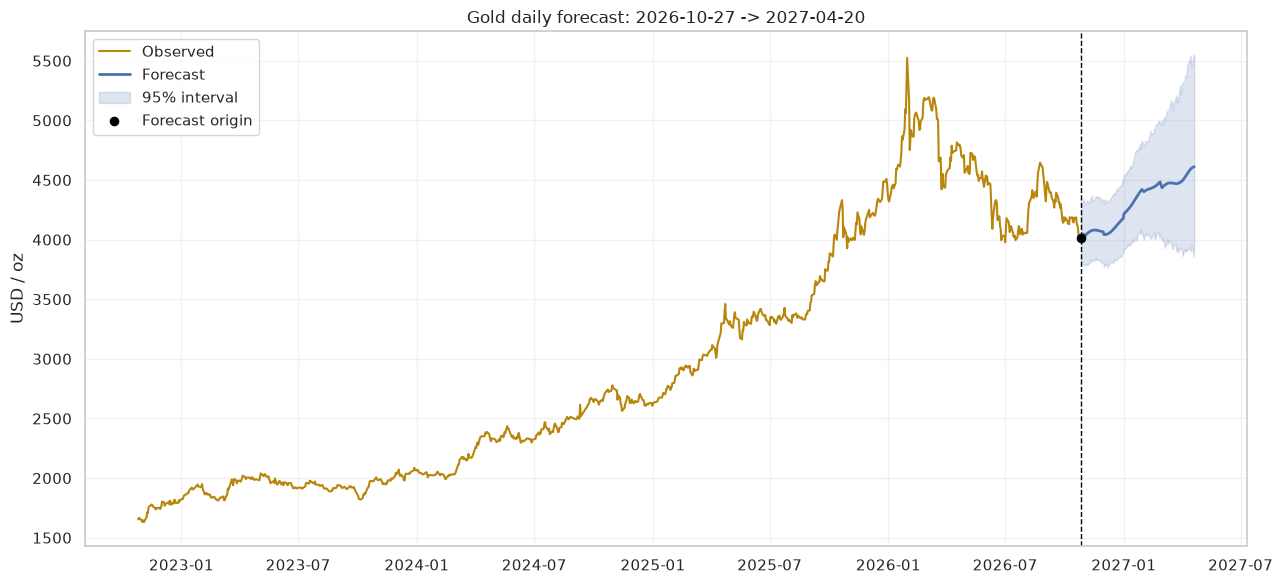

In [12]:
history_plot = model_df[model_df["ds"] >= model_df["ds"].max() - pd.DateOffset(years=4)]

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(history_plot["ds"], history_plot["gold"], color="#b8860b", lw=1.5, label="Observed")
ax.plot(forecast["ds"], forecast["yhat"], color="#4c72b0", lw=2, label="Forecast")
ax.fill_between(
    forecast["ds"], forecast["yhat_lower"], forecast["yhat_upper"],
    color="#4c72b0", alpha=0.18, label="95% interval",
)
ax.axvline(last_date, color="black", ls="--", lw=1)
ax.scatter([last_date], [last_actual], color="black", zorder=5, s=35, label="Forecast origin")
ax.set_title(
    f"Gold daily forecast: {forecast['ds'].min().date()} -> {forecast['ds'].max().date()}"
)
ax.set_ylabel("USD / oz")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "forecast_daily.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 10 — Holdout diagnostics

The final specification is evaluated again on the 24-month holdout. The plots and residuals show where the model works and where it fails:

- A good 2024-2025 fit does not guarantee a good 2026 fit.
- Residual autocorrelation indicates that daily errors are not independent; the 95% interval should be read as approximate.
- The model is a conditional forecast given the exogenous paths, not a market-timing signal.

Holdout anchored MAPE: 6.28% | RMSE: $413.6 | MAE: $273.4 | anchor: 1.0524


,ds,gold,pred_raw,pred,resid
2181,2024-10-28,2730.52,2591.447389,2727.355529,-3.164471
2182,2024-10-29,2748.98,2584.933166,2720.499669,-28.480331
2183,2024-10-30,2778.27,2586.838134,2722.504543,-55.765457
2184,2024-11-01,2751.64,2584.384238,2719.921952,-31.718048
2185,2024-11-04,2740.95,2538.058890,2671.167077,-69.782923


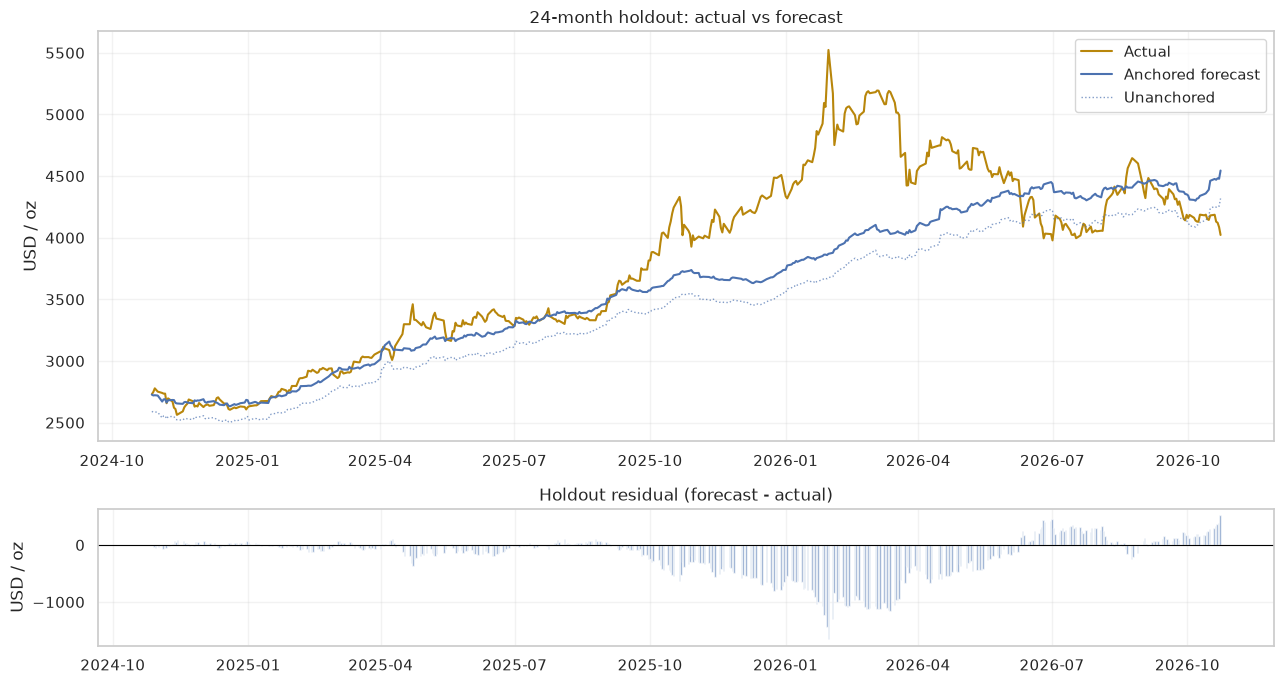

{'mean_usd': np.float64(-188.287), 'std_usd': np.float64(368.68), 'lag1_autocorrelation': np.float64(0.985), 'share_within_5pct': 56.871}


,year,MAPE,RMSE,MAE
0,2024,1.275940,39.564893,33.844620
1,2025,4.495444,259.429928,172.155594
2,2026,9.464026,574.321234,444.863685


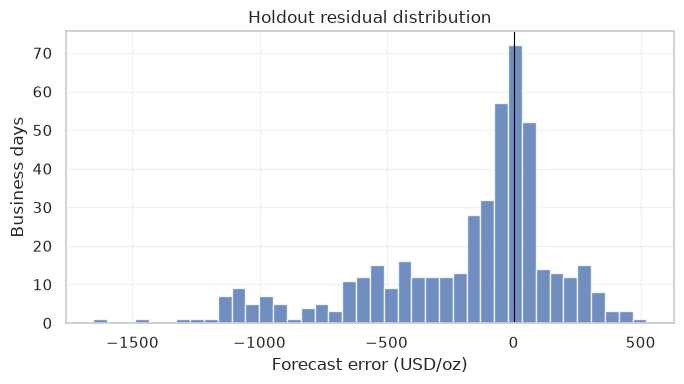

In [13]:
holdout = fit_and_evaluate(
    FINAL_REGS, cps=BEST_CPS, holdout_start=HOLDOUT_START, horizon_months=HOLDOUT_MONTHS
)
holdout_test = holdout["test"]

print(
    f"Holdout anchored MAPE: {holdout['MAPE']:.2f}% | "
    f"RMSE: ${holdout['RMSE']:,.1f} | MAE: ${holdout['MAE']:,.1f} | "
    f"anchor: {holdout['anchor_ratio']:.4f}"
)
display(holdout_test.head())

fig, axes = plt.subplots(2, 1, figsize=(13, 7), height_ratios=[3, 1])
axes[0].plot(holdout_test["ds"], holdout_test["gold"], color="#b8860b", lw=1.5, label="Actual")
axes[0].plot(holdout_test["ds"], holdout_test["pred"], color="#4c72b0", lw=1.5, label="Anchored forecast")
axes[0].plot(
    holdout_test["ds"], holdout_test["pred_raw"], color="#4c72b0",
    lw=1, ls=":", alpha=0.7, label="Unanchored",
)
axes[0].set_title("24-month holdout: actual vs forecast")
axes[0].set_ylabel("USD / oz")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].bar(holdout_test["ds"], holdout_test["resid"], width=1.0, color="#4c72b0", alpha=0.7)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Holdout residual (forecast - actual)")
axes[1].set_ylabel("USD / oz")
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "holdout_daily.png", dpi=150, bbox_inches="tight")
plt.show()

resid = holdout_test["resid"]
resid_stats = {
    "mean_usd": resid.mean(),
    "std_usd": resid.std(),
    "lag1_autocorrelation": resid.autocorr(1),
    "share_within_5pct": float((resid.abs() / holdout_test["gold"] < 0.05).mean() * 100),
}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in resid_stats.items()})

year_rows = []
for year, group in holdout_test.groupby(holdout_test["ds"].dt.year):
    metrics = error_metrics(group["gold"], group["pred"])
    year_rows.append({"year": int(year), **metrics})
year_table = pd.DataFrame(year_rows)
display(year_table)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(resid, bins=40, color="#4c72b0", alpha=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Holdout residual distribution")
ax.set_xlabel("Forecast error (USD/oz)")
ax.set_ylabel("Business days")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "residuals_daily.png", dpi=150, bbox_inches="tight")
plt.show()

holdout_test.to_csv(OUT / "holdout_predictions_daily.csv", index=False)
year_table.to_csv(OUT / "holdout_by_year_daily.csv", index=False)

## Step 11 — Save outputs and print the decision summary

All tables and figures are written to `model_building/output_daily/`. The notebook is reproducible with the fixed date range and paths in Step 0.

In [14]:
gold.rename(columns={"y": "gold"}).to_csv(OUT / "daily_target_clean.csv", index=False)
feature_panel.reset_index().to_csv(OUT / "feature_panel_daily.csv", index=False)
model_df.to_csv(OUT / "modeling_table_daily.csv", index=False)
future_regressors.to_csv(OUT / "future_regressors_daily.csv", index=False)
forecast.to_csv(OUT / "forecast_daily.csv", index=False)
qa_monthly.to_csv(OUT / "wgc_monthly_qa.csv")
outliers.to_csv(OUT / "target_outliers_daily.csv", index=False)
pd.Series(target_qa).to_csv(OUT / "target_qa_daily.csv")

print("Saved files:")
for path in sorted(OUT.glob("*")):
    print(f"  {path.name}")

print("\nDecision summary")
print(f"Target: daily Kitco USD, {len(gold):,} observations, {target_qa['final_start'].date()} -> {target_qa['final_end'].date()}")
print(f"Final regressors (lagged 1 business day): {', '.join(FINAL_REGS)}")
print(f"Model: log target, multiplicative seasonality, yearly=True, weekly=False, cps={BEST_CPS}")
print(f"24-month holdout: MAPE {holdout['MAPE']:.2f}% | RMSE ${holdout['RMSE']:,.1f}")
print(f"Walk-forward mean: MAPE {wf_mean['MAPE_anchored']:.2f}% | RMSE ${wf_mean['RMSE_anchored']:,.1f}")
print(f"Forecast origin: {last_date.date()} at ${last_actual:,.2f}")
print(f"6-month forecast: ${forecast['yhat'].iloc[-1]:,.2f} "
      f"({(forecast['yhat'].iloc[-1] / last_actual - 1) * 100:.1f}% vs origin)")

Saved files:
  ccf_daily.png
  correlation_daily.png
  cps_sensitivity_daily.csv
  cps_sensitivity_daily.png
  daily_target_clean.csv
  feature_panel_daily.csv
  forecast_daily.csv
  forecast_daily.png
  forecast_summary_daily.csv
  future_regressors_daily.csv
  gold_history_daily.png
  holdout_by_year_daily.csv
  holdout_daily.png
  holdout_predictions_daily.csv
  model_comparison_daily.csv
  modeling_table_daily.csv
  regressors_history_daily.png
  residuals_daily.png
  target_outliers_daily.csv
  target_qa_daily.csv
  walk_forward_daily.png
  walk_forward_metrics_daily.csv
  wgc_monthly_qa.csv
  wgc_qa_daily.png

Decision summary
Target: daily Kitco USD, 2,656 observations, 2015-02-05 -> 2026-10-26
Final regressors (lagged 1 business day): ust10y, dxy, fed_funds, cpi_yoy
Model: log target, multiplicative seasonality, yearly=True, weekly=False, cps=0.05
24-month holdout: MAPE 6.28% | RMSE $413.6
Walk-forward mean: MAPE 6.04% | RMSE $242.3
Forecast origin: 2026-10-26 at $4,015.80
6-mo

## Summary and limitations

**What the model does**

- Uses the daily Kitco USD price as the target, after robust date repair, duplicate resolution, and outlier control.
- Aligns daily market regressors and monthly macro regressors without look-ahead bias.
- Selects a compact set of four regressors: **10-year Treasury yield, US Dollar Index, Fed funds rate, and CPI year-over-year**.
- Uses a log-price Prophet with multiplicative seasonality, yearly seasonality, no weekly seasonality, and a 0.05 changepoint prior.
- Anchors the final forecast to the last observed price and evaluates that same anchoring rule on the holdout.
- Reports both a 24-month holdout and four rolling 12-month walk-forward folds.

**Why these choices**

- The full seven-regressor model and the four-regressor model were both tested. The compact model had the best anchored 24-month holdout error and a stable walk-forward profile, while avoiding the extra collinearity of Brent, GPR, and the S&P 500 once rates, the dollar, Fed policy, and inflation were included.
- Levels are used for the final regressors because they performed better out-of-sample than the change-based alternatives. This is an empirical result, not a claim that levels are structurally causal.
- The log target makes the error metric approximately percentage-based and prevents the forecast interval from becoming implausibly wide in dollar terms as the gold price level rises.
- Anchoring removes the artificial jump that occurs when a smooth trend model is refitted after a sharp final-week move. It is a nowcast correction, not a substitute for a better trend model.

**Limitations**

- The forecast is conditional on the auxiliary forecasts for yields, the dollar, Fed funds, and CPI. Those paths are highly uncertain; the gold interval does not include that uncertainty.
- Monthly macro variables are aligned with approximate release lags. Exact release calendars and revisions are not modelled.
- The daily target has many missing business days. Prophet handles the irregular dates, but intraweek dynamics are not fully observed.
- Residual autocorrelation and regime-dependent errors mean the 95% interval is approximate.
- Correlations and CCF are descriptive. They do not establish causality, and a model selected on one historical sample can fail in a new regime.
- This is a research/forecasting exercise, not investment advice.

**Practical next step**

Treat the forecast as a scenario baseline. Re-run the notebook when new data arrive, and stress-test the gold path under alternative yield, dollar, Fed, and inflation scenarios rather than relying on a single exogenous forecast.